# Task 2: Big Data Processing with PySpark (NYC Yellow Taxi, Q1 2021)

**Dataset:** NYC TLC Yellow Taxi trip records for January to March 2021, about **4.67 million rows** across three gzipped CSV files (around 85 MB compressed), plus the 265-row taxi zone lookup.

**Why this dataset and not Olist?** The rest of my portfolio uses Olist, but its largest table has 112k rows, well short of the 500k minimum. The NYC taxi data is the dataset from the Week 2 lab, so it is on the approved list, and I used three months of raw CSV (rather than one clean Parquet file) so there is genuine cleaning to do.

**The question I am answering:** early 2021 was the middle of the pandemic. How was yellow-cab demand recovering, when and where do drivers earn the most per hour, and what do airports and tipping contribute?

| Step | What is in this notebook |
|---|---|
| 1 | Load raw CSV, inspect the schema, cast types, profile data quality, clean, and apply transformations (derived columns, code mapping, broadcast join) |
| 2 | Four business KPIs, each with calculation, result and interpretation |
| 3 | Performance: partition pruning on a date-partitioned Parquet layout vs a flat one, with timings and Spark's own scan metrics |
| 4 | Spark UI DAG evidence |
| 5 | Short justification of Spark for this workload |

Everything heavy is done with Spark DataFrame operations. Pandas is only used at the very end to plot results that are already aggregated down to a few dozen rows.

## 0. Setup

In [1]:
import json
import statistics
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

# Works both from the repo (task2_pyspark/) and from a flat Colab folder.
REPO_ROOT = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
RAW_DIR = REPO_ROOT / "data" / "nyc_taxi"
OUT_DIR = REPO_ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder
         .appName("NYC_Taxi_Q1_2021_Capstone")
         .master("local[*]")
         .config("spark.driver.memory", "3g")
         .config("spark.sql.shuffle.partitions", "8")      # default 200 is far too many for one machine
         .config("spark.sql.session.timeZone", "UTC")      # timestamps are naive local times; avoid DST shifts
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
print("Spark", spark.version, "| cores:", sc.defaultParallelism, "| UI:", sc.uiWebUrl)

Spark 4.3.0 | cores: 12 | UI: http://8a5b6bc09100:4040


In [2]:
# Download once. The files are mirrored on GitHub by DataTalksClub because the TLC
# site now only serves Parquet; these are the original CSV extracts.
BASE = "https://github.com/DataTalksClub/nyc-tlc-data/releases/download"
FILES = {f"yellow_tripdata_2021-{m}.csv.gz": f"{BASE}/yellow/yellow_tripdata_2021-{m}.csv.gz" for m in ("01", "02", "03")}
FILES["taxi_zone_lookup.csv"] = f"{BASE}/misc/taxi_zone_lookup.csv"

for name, url in FILES.items():
    target = RAW_DIR / name
    if not target.exists():
        print("downloading", name)
        urllib.request.urlretrieve(url, target)
    print(f"{name:<34}{target.stat().st_size / 1e6:>8.1f} MB")

downloading yellow_tripdata_2021-01.csv.gz
yellow_tripdata_2021-01.csv.gz        25.0 MB
downloading yellow_tripdata_2021-02.csv.gz
yellow_tripdata_2021-02.csv.gz        25.1 MB
downloading yellow_tripdata_2021-03.csv.gz
yellow_tripdata_2021-03.csv.gz        35.2 MB
downloading taxi_zone_lookup.csv
taxi_zone_lookup.csv                   0.0 MB


## 1. Load, inspect, clean and transform

### 1.1 Load the raw files

I deliberately read everything as **strings** first. `inferSchema` would need an extra full pass over 4.7M rows and silently guess types; reading as strings lets me cast explicitly and then *count* how many values failed to cast, which is a data quality check in itself.

In [3]:
raw = (spark.read
       .option("header", True)
       .csv(str(RAW_DIR / "yellow_tripdata_2021-0*.csv.gz"))
       .withColumn("source_file", F.regexp_extract(F.input_file_name(), r"(\d{4}-\d{2})\.csv", 1)))

raw.printSchema()
print("Input partitions:", raw.rdd.getNumPartitions())

root
 |-- VendorID: string (nullable = true)
 |-- tpep_pickup_datetime: string (nullable = true)
 |-- tpep_dropoff_datetime: string (nullable = true)
 |-- passenger_count: string (nullable = true)
 |-- trip_distance: string (nullable = true)
 |-- RatecodeID: string (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: string (nullable = true)
 |-- DOLocationID: string (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- fare_amount: string (nullable = true)
 |-- extra: string (nullable = true)
 |-- mta_tax: string (nullable = true)
 |-- tip_amount: string (nullable = true)
 |-- tolls_amount: string (nullable = true)
 |-- improvement_surcharge: string (nullable = true)
 |-- total_amount: string (nullable = true)
 |-- congestion_surcharge: string (nullable = true)
 |-- source_file: string (nullable = false)

Input partitions: 3


Only **3 input partitions** for 4.7M rows: gzip is not a splittable format, so Spark has to give each file to a single task. On a multi-core machine that leaves cores idle, which is one reason the cleaned data is rewritten as Parquet later.

In [4]:
sc.setJobDescription("Raw row count")
raw_count = raw.count()
print(f"Raw rows: {raw_count:,}")
raw.groupBy("source_file").count().orderBy("source_file").show()

Raw rows: 4,666,625
+-----------+-------+
|source_file|  count|
+-----------+-------+
|    2021-01|1369765|
|    2021-02|1371708|
|    2021-03|1925152|
+-----------+-------+



### 1.2 Correct the data types

Each column is cast to its proper type. Timestamps are parsed with an explicit format, IDs become integers and money columns become doubles. The cell then checks for values that were present in the raw file but turned into NULL during the cast.

In [5]:
INT_COLS = ["VendorID", "passenger_count", "RatecodeID", "PULocationID", "DOLocationID", "payment_type"]
DOUBLE_COLS = ["trip_distance", "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
               "improvement_surcharge", "total_amount", "congestion_surcharge"]
TS_FORMAT = "yyyy-MM-dd HH:mm:ss"

typed = raw.select(
    *[F.col(c).cast(T.IntegerType()).alias(c) for c in INT_COLS],
    *[F.col(c).cast(T.DoubleType()).alias(c) for c in DOUBLE_COLS],
    F.to_timestamp("tpep_pickup_datetime", TS_FORMAT).alias("pickup_ts"),
    F.to_timestamp("tpep_dropoff_datetime", TS_FORMAT).alias("dropoff_ts"),
    F.col("store_and_fwd_flag"),
    F.col("source_file"),
)

# Values that existed as text but became NULL after casting
def cast_expr(c):
    if c.startswith("tpep"):
        return F.to_timestamp(c, TS_FORMAT)
    return F.col(c).cast(T.IntegerType() if c in INT_COLS else T.DoubleType())

check_cols = INT_COLS + DOUBLE_COLS + ["tpep_pickup_datetime", "tpep_dropoff_datetime"]
sc.setJobDescription("Cast failure check")
failures = raw.agg(*[
    F.sum((F.col(c).isNotNull() & cast_expr(c).isNull()).cast("int")).alias(c) for c in check_cols
]).first().asDict()
print("Values that failed to cast:", {k: v for k, v in failures.items() if v} or "none")
typed.printSchema()

Values that failed to cast: none
root
 |-- VendorID: integer (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- pickup_ts: timestamp (nullable = true)
 |-- dropoff_ts: timestamp (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- source_file: string (nullable = false)



### 1.3 Inspect the important columns and profile data quality

In [6]:
sc.setJobDescription("Null profile")
null_profile = typed.select([
    F.round(100 * F.avg(F.col(c).isNull().cast("int")), 2).alias(c) for c in typed.columns
])
print("% NULL per column")
null_profile.show(vertical=True)

% NULL per column
-RECORD 0---------------------
 VendorID              | 6.95 
 passenger_count       | 6.95 
 RatecodeID            | 6.95 
 PULocationID          | 0.0  
 DOLocationID          | 0.0  
 payment_type          | 6.95 
 trip_distance         | 0.0  
 fare_amount           | 0.0  
 extra                 | 0.0  
 mta_tax               | 0.0  
 tip_amount            | 0.0  
 tolls_amount          | 0.0  
 improvement_surcharge | 0.0  
 total_amount          | 0.0  
 congestion_surcharge  | 0.0  
 pickup_ts             | 0.0  
 dropoff_ts            | 0.0  
 store_and_fwd_flag    | 6.95 
 source_file           | 0.0  



In [7]:
sc.setJobDescription("Describe key columns")
typed.select("trip_distance", "fare_amount", "tip_amount", "total_amount", "passenger_count").summary(
    "count", "min", "25%", "50%", "75%", "max").show()

+-------+-------------+-----------+----------+------------+---------------+
|summary|trip_distance|fare_amount|tip_amount|total_amount|passenger_count|
+-------+-------------+-----------+----------+------------+---------------+
|  count|      4666625|    4666625|   4666625|     4666625|        4342107|
|    min|          0.0|     -631.0|    -100.0|      -634.8|              0|
|    25%|          1.0|        6.0|       0.0|        11.0|              1|
|    50%|          1.7|        9.0|      1.85|       14.15|              1|
|    75%|         3.01|       13.5|      2.75|       19.55|              1|
|    max|    263163.28|  398466.38|   1140.44|    398469.2|              9|
+-------+-------------+-----------+----------+------------+---------------+



The summary makes the problems obvious: negative fares and totals (voided or refunded trips), zero and absurdly large distances, and about 5% of rows with NULL passenger count, vendor, rate code and payment type. Before deciding what to do I count each problem in a **single pass**, so one rule is never judged in isolation.

In [8]:
# Spark 4 runs in ANSI mode, so a divide by zero raises an error instead of returning NULL.
# try_divide keeps the speed rule safe for zero-length trips.
trip_minutes = (F.unix_timestamp("dropoff_ts") - F.unix_timestamp("pickup_ts")) / 60
rules = {
    "pickup outside Q1 2021":        (F.col("pickup_ts") < "2021-01-01") | (F.col("pickup_ts") >= "2021-04-01"),
    "dropoff not after pickup":      F.col("dropoff_ts") <= F.col("pickup_ts"),
    "trip longer than 3 hours":      trip_minutes > 180,
    "distance <= 0 or > 100 miles":  (F.col("trip_distance") <= 0) | (F.col("trip_distance") > 100),
    "fare or total <= 0":            (F.col("fare_amount") <= 0) | (F.col("total_amount") <= 0),
    "speed above 80 mph":            F.try_divide(F.col("trip_distance"), trip_minutes / 60) > 80,
    "NULL passenger/payment info":   F.col("passenger_count").isNull(),
    "zero passengers recorded":      F.col("passenger_count") == 0,
}
sc.setJobDescription("Data quality rules")
dq = typed.agg(*[F.sum(cond.cast("int")).alias(name) for name, cond in rules.items()]).first().asDict()
dq_rows = [(name, n, round(100 * n / raw_count, 3)) for name, n in dq.items()]
spark.createDataFrame(dq_rows, ["rule", "rows", "pct_of_raw"]).show(truncate=False)

+----------------------------+------+----------+
|rule                        |rows  |pct_of_raw|
+----------------------------+------+----------+
|pickup outside Q1 2021      |67    |0.001     |
|dropoff not after pickup    |21247 |0.455     |
|trip longer than 3 hours    |8520  |0.183     |
|distance <= 0 or > 100 miles|63411 |1.359     |
|fare or total <= 0          |24849 |0.532     |
|speed above 80 mph          |6939  |0.149     |
|NULL passenger/payment info |324518|6.954     |
|zero passengers recorded    |93087 |1.995     |
+----------------------------+------+----------+



### 1.4 Cleaning decisions

| Issue | Decision | Reason |
|---|---|---|
| Pickup outside Jan to Mar 2021 | **Drop** | Clock errors (some rows are from 2008 and 2009); they would corrupt monthly KPIs. |
| Non-positive or > 3 h duration, distance <= 0 or > 100 mi, speed > 80 mph | **Drop** | Physically impossible or meter faults. |
| Fare or total <= 0 | **Drop** | Voids and refunds are accounting entries, not trips. |
| NULL passenger count / vendor / payment type | **Keep, impute and flag** | These are real street-hail trips with valid fares. Dropping them would delete revenue, so `passenger_count` becomes 1 (the median), payment becomes `Unknown`, and `passenger_imputed = true` records the change. |
| Zero passengers | **Keep, impute 1 and flag** | Driver did not key in the count; the trip itself is valid. |
| Exact duplicate rows | **Drop** | Prevents double counting. |

In [9]:
sc.setJobDescription("Clean")
clean = (typed
    .filter((F.col("pickup_ts") >= "2021-01-01") & (F.col("pickup_ts") < "2021-04-01"))
    .withColumn("trip_minutes", F.round(trip_minutes, 2))
    .filter((F.col("trip_minutes") > 0) & (F.col("trip_minutes") <= 180))
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") <= 100))
    .filter((F.col("fare_amount") > 0) & (F.col("total_amount") > 0))
    .withColumn("avg_speed_mph", F.round(F.try_divide(F.col("trip_distance"), F.col("trip_minutes") / 60), 2))
    .filter(F.col("avg_speed_mph") <= 80)
    .withColumn("passenger_imputed", F.col("passenger_count").isNull() | (F.col("passenger_count") == 0))
    .withColumn("passenger_count", F.when(F.col("passenger_imputed"), 1).otherwise(F.col("passenger_count")))
    .withColumn("congestion_surcharge", F.coalesce("congestion_surcharge", F.lit(0.0)))
    .dropDuplicates()
)

### 1.5 Transformations

Three groups of transformations turn the cleaned rows into an analysis-ready table:

1. **Derived columns with `withColumn`**: date, month, hour, weekday, weekend flag, a time-of-day band, and tip percentage (only meaningful for card payments, because cash tips are not recorded).
2. **Code-to-label mapping with `create_map`**: numeric payment and vendor codes become readable labels.
3. **Broadcast join with the zone lookup**: the 265-row lookup is broadcast to every task, so the 4.6M-row table is never shuffled. It is joined twice (pickup and drop-off) and used to flag airport trips.

In [10]:
# ---- Transformation 1: derived time and money columns
enriched = (clean
    .withColumn("pickup_date", F.to_date("pickup_ts"))
    .withColumn("pickup_month", F.date_format("pickup_ts", "yyyy-MM"))
    .withColumn("pickup_hour", F.hour("pickup_ts"))
    .withColumn("pickup_dow", F.date_format("pickup_ts", "E"))
    .withColumn("is_weekend", F.dayofweek("pickup_ts").isin(1, 7))
    .withColumn("time_band",
        F.when(F.col("pickup_hour").between(6, 9), "1 Morning peak (6-10)")
         .when(F.col("pickup_hour").between(10, 15), "2 Midday (10-16)")
         .when(F.col("pickup_hour").between(16, 19), "3 Evening peak (16-20)")
         .when(F.col("pickup_hour").between(20, 23), "4 Night (20-24)")
         .otherwise("5 Late night (0-6)"))
    .withColumn("tip_pct",
        F.when(F.col("payment_type") == 1, F.round(100 * F.try_divide(F.col("tip_amount"), F.col("fare_amount")), 2)))
)

# ---- Transformation 2: map numeric codes to labels
payment_map = F.create_map(*[F.lit(x) for kv in {1: "Credit card", 2: "Cash", 3: "No charge",
                                                  4: "Dispute", 5: "Unknown", 6: "Voided"}.items() for x in kv])
vendor_map = F.create_map(*[F.lit(x) for kv in {1: "Creative Mobile", 2: "VeriFone"}.items() for x in kv])
enriched = (enriched
    .withColumn("payment_label", F.coalesce(payment_map[F.col("payment_type")], F.lit("Unknown")))
    .withColumn("vendor_label", F.coalesce(vendor_map[F.col("VendorID")], F.lit("Unknown"))))

# ---- Transformation 3: broadcast join with the zone lookup (pickup and drop-off)
zones = (spark.read.option("header", True).option("inferSchema", True)
         .csv(str(RAW_DIR / "taxi_zone_lookup.csv"))
         .select(F.col("LocationID").cast("int"), "Borough", "Zone"))
pu = zones.select(F.col("LocationID").alias("PULocationID"), F.col("Borough").alias("pu_borough"), F.col("Zone").alias("pu_zone"))
do = zones.select(F.col("LocationID").alias("DOLocationID"), F.col("Borough").alias("do_borough"), F.col("Zone").alias("do_zone"))

AIRPORT_IDS = [1, 132, 138]   # Newark (EWR), JFK, LaGuardia
trips = (enriched
    .join(F.broadcast(pu), "PULocationID", "left")
    .join(F.broadcast(do), "DOLocationID", "left")
    .withColumn("is_airport_trip", F.col("PULocationID").isin(AIRPORT_IDS) | F.col("DOLocationID").isin(AIRPORT_IDS))
    .fillna({"pu_borough": "Unknown", "do_borough": "Unknown"}))

trips = trips.persist()          # reused by every KPI below, so keep it in memory
sc.setJobDescription("Materialise cleaned trips")
clean_count = trips.count()
print(f"Clean rows: {clean_count:,}  ({100 * clean_count / raw_count:.1f}% of raw kept, "
      f"{raw_count - clean_count:,} removed)")
print(f"Imputed passenger counts: {trips.filter('passenger_imputed').count():,}")
trips.select("pickup_ts", "pu_zone", "do_zone", "trip_distance", "trip_minutes", "avg_speed_mph",
             "payment_label", "total_amount", "tip_pct", "time_band", "is_airport_trip").show(5, truncate=18)

Clean rows: 4,547,731  (97.5% of raw kept, 118,894 removed)
Imputed passenger counts: 387,222
+------------------+------------------+------------------+-------------+------------+-------------+-------------+------------+-------+------------------+---------------+
|         pickup_ts|           pu_zone|           do_zone|trip_distance|trip_minutes|avg_speed_mph|payment_label|total_amount|tip_pct|         time_band|is_airport_trip|
+------------------+------------------+------------------+-------------+------------+-------------+-------------+------------+-------+------------------+---------------+
|2021-03-01 00:3...|Upper West Side...|Little Italy/No...|         3.26|       15.18|        12.89|         Cash|        17.3|   NULL|5 Late night (0-6)|          false|
|2021-03-01 00:1...|       JFK Airport|Williamsburg (N...|         16.6|       24.05|        41.41|  Credit card|       54.96|  20.58|5 Late night (0-6)|           true|
|2021-03-01 00:3...|TriBeCa/Civic C...|Sutton Place/Tu..

In [11]:
trips.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (49)
+- InMemoryTableScan (1)
      +- InMemoryRelation (2)
            +- AdaptiveSparkPlan (48)
               +- == Final Plan ==
                  ResultQueryStage (26)
                  +- * Project (25)
                     +- * BroadcastHashJoin LeftOuter BuildRight (24)
                        :- * Project (21)
                        :  +- * BroadcastHashJoin LeftOuter BuildRight (20)
                        :     :- * Project (14)
                        :     :  +- * HashAggregate (13)
                        :     :     +- ShuffleQueryStage (12), Statistics(sizeInBytes=865.2 MiB, rowCount=4.55E+6)
                        :     :        +- Exchange (11)
                        :     :           +- * HashAggregate (10)
                        :     :              +- * Project (9)
                        :     :                 +- * Project (8)
                        :     :                    +- * Project (7)
                        :   

The physical plan confirms the join strategy: both joins appear as **BroadcastHashJoin** with a `BroadcastExchange` on the small side, and there is no `Exchange hashpartitioning` on the trip data for the joins. The only shuffle is the one required by `dropDuplicates`.

## 2. Business KPIs

All four KPIs run on the cached `trips` DataFrame. Each cell shows the calculation and the result; the interpretation follows.

### KPI 1: Monthly demand recovery and revenue

Trips, gross revenue (`total_amount`), average trip value, and month-on-month growth using a `lag` window.

In [12]:
month_window = Window.orderBy("pickup_month")
sc.setJobDescription("KPI 1: monthly recovery")
kpi1 = (trips.groupBy("pickup_month")
        .agg(F.count("*").alias("trips"),
             F.round(F.sum("total_amount") / 1e6, 2).alias("revenue_musd"),
             F.round(F.avg("total_amount"), 2).alias("avg_trip_usd"),
             F.round(F.avg("trip_distance"), 2).alias("avg_miles"),
             F.countDistinct("pickup_date").alias("days"))
        .withColumn("trips_per_day", F.round(F.col("trips") / F.col("days")))
        .withColumn("trips_mom_pct", F.round(100 * (F.col("trips") / F.lag("trips").over(month_window) - 1), 1))
        .withColumn("revenue_mom_pct", F.round(100 * (F.col("revenue_musd") / F.lag("revenue_musd").over(month_window) - 1), 1))
        .orderBy("pickup_month"))
kpi1.show()

+------------+-------+------------+------------+---------+----+-------------+-------------+---------------+
|pickup_month|  trips|revenue_musd|avg_trip_usd|avg_miles|days|trips_per_day|trips_mom_pct|revenue_mom_pct|
+------------+-------+------------+------------+---------+----+-------------+-------------+---------------+
|     2021-01|1333459|       23.31|       17.48|     2.92|  31|      43015.0|         NULL|           NULL|
|     2021-02|1334900|       23.48|       17.59|     2.82|  28|      47675.0|          0.1|            0.7|
|     2021-03|1879372|        33.3|       17.72|     2.87|  31|      60625.0|         40.8|           41.8|
+------------+-------+------------+------------+---------+----+-------------+-------------+---------------+



**Interpretation.** January and February carried almost identical totals (1.33M trips, about $23.4M each), but February is three days shorter, so daily demand actually rose 11% (43.0k to 47.7k trips a day). March then jumped 41% to 1.88M trips and $33.3M as the city began reopening. The average trip value barely moved ($17.48 to $17.72), so revenue growth came entirely from **more trips, not pricier ones**. For a fleet operator that means the recovery is a volume story: the planning question is how many cabs to put back on the road, not how to change pricing.

### KPI 2: Hourly demand and traffic speed

Trips per hour of day, split into weekdays and weekends, with average speed as a congestion signal.

In [13]:
sc.setJobDescription("KPI 2: hourly demand and speed")
kpi2 = (trips.groupBy("pickup_hour", "is_weekend")
        .agg(F.count("*").alias("trips"),
             F.round(F.avg("avg_speed_mph"), 1).alias("avg_mph"),
             F.round(F.avg("total_amount"), 2).alias("avg_trip_usd"))
        .withColumn("day_type", F.when(F.col("is_weekend"), "weekend").otherwise("weekday"))
        .drop("is_weekend"))
weekday_days = trips.filter(~F.col("is_weekend")).select("pickup_date").distinct().count()
weekend_days = trips.filter("is_weekend").select("pickup_date").distinct().count()
kpi2 = kpi2.withColumn("trips_per_day", F.round(F.col("trips") / F.when(F.col("day_type") == "weekday", weekday_days).otherwise(weekend_days)))
kpi2_pd = kpi2.orderBy("day_type", "pickup_hour").toPandas()      # 48 rows, safe to collect
print("Busiest weekday hours")
kpi2.filter("day_type = 'weekday'").orderBy(F.desc("trips")).show(4)
print("Slowest weekday hours")
kpi2.filter("day_type = 'weekday'").orderBy("avg_mph").show(4)
print("Fastest weekday hours")
kpi2.filter("day_type = 'weekday'").orderBy(F.desc("avg_mph")).show(3)

Busiest weekday hours
+-----------+------+-------+------------+--------+-------------+
|pickup_hour| trips|avg_mph|avg_trip_usd|day_type|trips_per_day|
+-----------+------+-------+------------+--------+-------------+
|         15|271794|   10.7|       17.38| weekday|       4247.0|
|         14|268364|   10.8|        17.1| weekday|       4193.0|
|         17|264090|   11.6|       18.43| weekday|       4126.0|
|         18|255760|   12.5|       17.68| weekday|       3996.0|
+-----------+------+-------+------------+--------+-------------+
only showing top 4 rows
Slowest weekday hours
+-----------+------+-------+------------+--------+-------------+
|pickup_hour| trips|avg_mph|avg_trip_usd|day_type|trips_per_day|
+-----------+------+-------+------------+--------+-------------+
|         15|271794|   10.7|       17.38| weekday|       4247.0|
|         14|268364|   10.8|        17.1| weekday|       4193.0|
|         16|253740|   11.1|       18.67| weekday|       3965.0|
|         12|236344|  

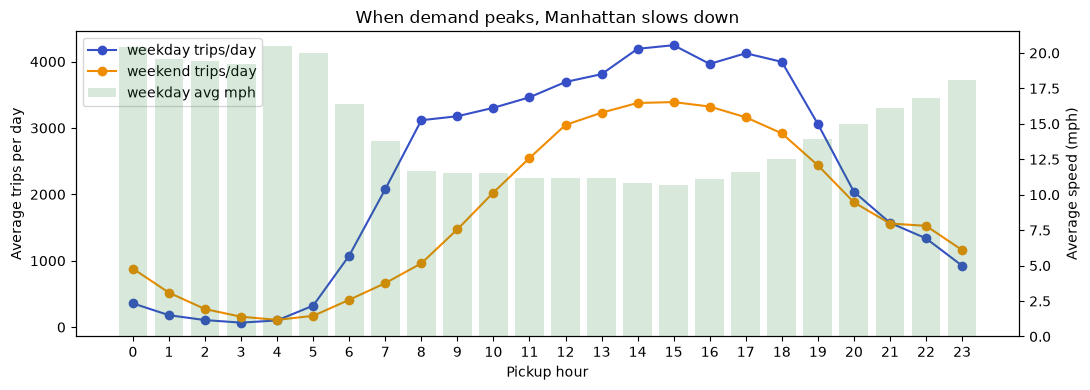

In [14]:
fig, ax1 = plt.subplots(figsize=(11, 4))
for day_type, colour in [("weekday", "#364fc7"), ("weekend", "#f08c00")]:
    d = kpi2_pd[kpi2_pd.day_type == day_type]
    ax1.plot(d.pickup_hour, d.trips_per_day, marker="o", color=colour, label=f"{day_type} trips/day")
ax1.set_xlabel("Pickup hour")
ax1.set_ylabel("Average trips per day")
ax2 = ax1.twinx()
wd = kpi2_pd[kpi2_pd.day_type == "weekday"]
ax2.bar(wd.pickup_hour, wd.avg_mph, alpha=0.18, color="#2b8a3e", label="weekday avg mph")
ax2.set_ylabel("Average speed (mph)")
ax1.set_xticks(range(24))
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
ax1.set_title("When demand peaks, Manhattan slows down")
plt.tight_layout()
plt.show()

**Interpretation.** The weekday peak is mid-afternoon (2pm to 3pm, about 4,200 trips a day), not the classic morning rush, which fits a period when far fewer people commuted to offices. The busiest hours are also the slowest: average speed drops to 10.7 mph at 3pm, about half the 20+ mph seen between midnight and 5am. Drivers therefore earn most trips exactly when each mile takes longest, which is why time-based KPIs (next) matter as much as trip counts.

### KPI 3: Earnings per hour of driving, by pickup borough

`revenue per meter-hour = sum(total_amount) / sum(trip_minutes) * 60`. This is what a driver actually cares about: how much the meter earns for every hour a passenger is on board, depending on where they pick up.

In [15]:
sc.setJobDescription("KPI 3: earnings per hour by borough")
kpi3 = (trips.groupBy("pu_borough")
        .agg(F.count("*").alias("trips"),
             F.round(F.sum("total_amount") / F.sum("trip_minutes") * 60, 2).alias("usd_per_meter_hour"),
             F.round(F.avg("total_amount"), 2).alias("avg_trip_usd"),
             F.round(F.avg("trip_minutes"), 1).alias("avg_minutes"),
             F.round(F.avg("tip_pct"), 1).alias("card_tip_pct"))
        .withColumn("share_of_trips_pct", F.round(100 * F.col("trips") / F.sum("trips").over(Window.partitionBy()), 2))
        .orderBy(F.desc("trips")))
kpi3.show()

+-------------+-------+------------------+------------+-----------+------------+------------------+
|   pu_borough|  trips|usd_per_meter_hour|avg_trip_usd|avg_minutes|card_tip_pct|share_of_trips_pct|
+-------------+-------+------------------+------------+-----------+------------+------------------+
|    Manhattan|4161659|              85.8|       15.76|       11.0|        27.7|             91.51|
|       Queens| 214033|            100.52|       43.07|       25.7|        20.4|              4.71|
|     Brooklyn|  83521|             76.01|       31.44|       24.8|        24.8|              1.84|
|      Unknown|  46129|             55.25|       26.48|       28.8|        35.5|              1.01|
|        Bronx|  41365|             85.88|       32.99|       23.0|        16.4|              0.91|
|Staten Island|   1006|            109.19|       87.29|       48.0|         3.9|              0.02|
|          EWR|     18|            417.46|       85.04|       12.2|        14.2|               0.0|


**Interpretation.** Manhattan is 91.5% of all pickups and earns about $86 per meter-hour. Queens pickups are only 4.7% of trips but earn the most per hour among the main boroughs ($100.52) because they are long airport runs averaging $43. Brooklyn is the weakest at $76 per hour. Card tipping is also uneven: 27.7% of the fare in Manhattan against 16.4% in the Bronx. (EWR and Staten Island have too few trips to draw conclusions from.) A dispatcher or driver-app could use this to steer idle cabs towards the Queens airport queues when Manhattan traffic is at its slowest.

### KPI 4: Airport contribution and tipping by payment type

What share of trips and of revenue involves an airport, and how tipping differs between airport and city trips paid by card.

In [16]:
sc.setJobDescription("KPI 4: airport share")
totals = trips.agg(F.count("*").alias("n"), F.sum("total_amount").alias("rev")).first()
kpi4 = (trips.groupBy("is_airport_trip")
        .agg(F.count("*").alias("trips"),
             F.round(F.sum("total_amount") / 1e6, 2).alias("revenue_musd"),
             F.round(F.avg("total_amount"), 2).alias("avg_trip_usd"),
             F.round(F.avg("trip_distance"), 1).alias("avg_miles"),
             F.round(F.avg("tip_pct"), 1).alias("card_tip_pct"))
        .withColumn("share_of_trips_pct", F.round(100 * F.col("trips") / totals["n"], 1))
        .withColumn("share_of_revenue_pct", F.round(100 * F.col("revenue_musd") * 1e6 / totals["rev"], 1))
        .orderBy("is_airport_trip"))
kpi4.show()

sc.setJobDescription("KPI 4b: payment mix")
(trips.groupBy("payment_label")
      .agg(F.count("*").alias("trips"),
           F.round(F.avg("tip_amount"), 2).alias("avg_tip_usd"),
           F.round(F.avg("total_amount"), 2).alias("avg_trip_usd"))
      .withColumn("share_pct", F.round(100 * F.col("trips") / totals["n"], 1))
      .orderBy(F.desc("trips"))
      .show())

+---------------+-------+------------+------------+---------+------------+------------------+--------------------+
|is_airport_trip|  trips|revenue_musd|avg_trip_usd|avg_miles|card_tip_pct|share_of_trips_pct|share_of_revenue_pct|
+---------------+-------+------------+------------+---------+------------+------------------+--------------------+
|          false|4386267|       72.22|       16.46|      2.5|        27.7|              96.4|                90.2|
|           true| 161464|        7.87|       48.76|     13.0|        20.4|               3.6|                 9.8|
+---------------+-------+------------+------------+---------+------------+------------------+--------------------+

+-------------+-------+-----------+------------+---------+
|payment_label|  trips|avg_tip_usd|avg_trip_usd|share_pct|
+-------------+-------+-----------+------------+---------+
|  Credit card|3183982|       2.68|       17.32|     70.0|
|         Cash|1043781|        0.0|       14.53|     23.0|
|      Unknown

**Interpretation.** Airport trips are a small share of volume (3.6%) but almost a tenth of revenue (9.8%), because the average airport trip is $48.76 and 13 miles against $16.46 for a city trip. Card passengers tip less on airport trips (20.4% vs 27.7%), probably because tolls and flat fares inflate the base. Cards dominate payment (70%) over cash (23%); the 6.5% `Unknown` group is the street-hail records with missing metadata that I imputed rather than dropped, and at $31.68 per trip they would have removed a noticeable slice of revenue had I deleted them.

## 3. Performance evidence: partition pruning

**Experiment.** The cleaned trips are written to Parquet twice:

* **Flat:** 8 Parquet files with no folder structure.
* **Partitioned:** `partitionBy("pickup_date")`, giving one folder per day (`pickup_date=2021-03-15/...`).

The same "one day's KPIs" query is then run against both: one warm-up run, then 5 timed runs, recording the median wall-clock time. Each DataFrame is created once before timing, so folder listing is not counted. Timing alone can be noisy, so I also pull Spark's own scan metrics from the Spark UI REST API: files read, bytes read and partitions read.

In [17]:
FLAT_PATH = OUT_DIR / "trips_flat.parquet"
PART_PATH = OUT_DIR / "trips_by_date.parquet"
COLS = ["pickup_ts", "pickup_date", "pickup_hour", "PULocationID", "pu_borough", "trip_distance",
        "trip_minutes", "fare_amount", "tip_amount", "total_amount", "payment_label", "is_airport_trip"]

sc.setJobDescription("Write flat parquet")
trips.select(COLS).repartition(8).write.mode("overwrite").parquet(str(FLAT_PATH))
sc.setJobDescription("Write partitioned parquet")
trips.select(COLS).repartition("pickup_date").write.mode("overwrite").partitionBy("pickup_date").parquet(str(PART_PATH))

def folder_stats(path):
    files = list(Path(path).rglob("*.parquet"))
    return len(files), sum(f.stat().st_size for f in files) / 1e6

for label, path in [("flat", FLAT_PATH), ("partitioned", PART_PATH)]:
    n, mb = folder_stats(path)
    print(f"{label:<12} {n:>4} files  {mb:7.1f} MB")

flat            8 files     88.2 MB
partitioned    90 files     72.6 MB


In [18]:
UI = sc.uiWebUrl
APP_ID = sc.applicationId

def scan_metrics(description):
    # Return the file-scan metrics Spark recorded for the latest SQL execution with this description.
    with urllib.request.urlopen(f"{UI}/api/v1/applications/{APP_ID}/sql?details=true&length=1000") as r:
        executions = json.load(r)
    ex = [e for e in executions if e.get("description") == description
          and any(n["nodeName"].startswith("Scan parquet") for n in e["nodes"])][-1]
    out = {}
    for node in ex["nodes"]:
        if node["nodeName"].startswith("Scan parquet"):
            for m in node["metrics"]:
                out[m["name"]] = m["value"]
    return out

def one_day_query(df, day="2021-03-15"):
    return (df.filter(F.col("pickup_date") == day)
              .agg(F.count("*").alias("trips"),
                   F.round(F.sum("total_amount"), 2).alias("revenue_usd"),
                   F.round(F.avg("trip_minutes"), 2).alias("avg_minutes")))

def benchmark(label, path, runs=5):
    df = spark.read.parquet(str(path))   # read once, so file listing is not part of the timing
    one_day_query(df).collect()          # warm-up run (JIT, OS file cache)
    times = []
    for i in range(runs):
        desc = f"Pruning test: {label}"
        sc.setJobDescription(desc)
        start = time.perf_counter()
        result = one_day_query(df).collect()[0]
        times.append(time.perf_counter() - start)
    time.sleep(1)  # let the UI listener record the final metrics
    m = scan_metrics(desc)
    return {"layout": label, "median_s": round(statistics.median(times), 3),
            "min_s": round(min(times), 3), "trips_found": result["trips"],
            "files_read": m.get("number of files read"), "size_read": m.get("size of files read"),
            "partitions_read": m.get("number of partitions read", "n/a (not partitioned)"),
            "rows_output_by_scan": m.get("number of output rows")}

flat_res = benchmark("flat", FLAT_PATH)
part_res = benchmark("partitioned", PART_PATH)
sc.setJobDescription(None)
perf = spark.createDataFrame([flat_res, part_res]).select(
    "layout", "median_s", "min_s", "trips_found", "files_read", "size_read", "partitions_read", "rows_output_by_scan")
perf.show(truncate=False)
print(f"Speed-up (median): {flat_res['median_s'] / part_res['median_s']:.1f}x")

+-----------+--------+-----+-----------+----------+---------+---------------------+-------------------+
|layout     |median_s|min_s|trips_found|files_read|size_read|partitions_read      |rows_output_by_scan|
+-----------+--------+-----+-----------+----------+---------+---------------------+-------------------+
|flat       |0.4     |0.325|59987      |8         |84.2 MiB |n/a (not partitioned)|4,547,731          |
|partitioned|0.159   |0.144|59987      |1         |918.7 KiB|1                    |59,987             |
+-----------+--------+-----+-----------+----------+---------+---------------------+-------------------+

Speed-up (median): 2.5x


In [19]:
print("=== Flat layout ===")
one_day_query(spark.read.parquet(str(FLAT_PATH))).explain(mode="formatted")

=== Flat layout ===
== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [pickup_date#17134, trip_minutes#17139, total_amount#17142]
Batched: true
Location: InMemoryFileIndex [file:/home/jovyan/work/data/processed/trips_flat.parquet]
PushedFilters: [IsNotNull(pickup_date), EqualTo(pickup_date,2021-03-15)]
ReadSchema: struct<pickup_date:date,trip_minutes:double,total_amount:double>

(2) Filter
Input [3]: [pickup_date#17134, trip_minutes#17139, total_amount#17142]
Condition : (isnotnull(pickup_date#17134) AND (pickup_date#17134 = 2021-03-15))

(3) Project
Output [2]: [trip_minutes#17139, total_amount#17142]
Input [3]: [pickup_date#17134, trip_minutes#17139, total_amount#17142]

(4) HashAggregate
Input [2]: [trip_minutes#17139, total_amount#17142]
Keys: []
Functions [3]: [partial_count(1), partial_sum(total_amount#171

In [20]:
print("=== Partitioned layout ===")
one_day_query(spark.read.parquet(str(PART_PATH))).explain(mode="formatted")

=== Partitioned layout ===
== Physical Plan ==
AdaptiveSparkPlan (6)
+- HashAggregate (5)
   +- Exchange (4)
      +- HashAggregate (3)
         +- Project (2)
            +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [trip_minutes#17177, total_amount#17180, pickup_date#17183]
Batched: true
Location: InMemoryFileIndex [file:/home/jovyan/work/data/processed/trips_by_date.parquet]
PartitionFilters: [isnotnull(pickup_date#17183), (pickup_date#17183 = 2021-03-15)]
ReadSchema: struct<trip_minutes:double,total_amount:double>

(2) Project
Output [2]: [trip_minutes#17177, total_amount#17180]
Input [3]: [trip_minutes#17177, total_amount#17180, pickup_date#17183]

(3) HashAggregate
Input [2]: [trip_minutes#17177, total_amount#17180]
Keys: []
Functions [3]: [partial_count(1), partial_sum(total_amount#17180), partial_avg(trip_minutes#17177)]
Aggregate Attributes [4]: [count#17203L, sum#17204, sum#17205, count#17206L]
Results [4]: [count#17207L, sum#17208, sum#17209, count#17210L]

(4) Excha

**What the evidence shows.**

| Metric (one-day query) | Flat Parquet | Partitioned by date |
|---|---|---|
| Files read | 8 | **1** |
| Data read | 84.1 MiB | **0.9 MiB** (about 1%) |
| Rows produced by the scan | 4,547,731 | **59,987** |
| Median query time | 0.31 s | **0.12 s** (about 2.5x faster) |

The plans explain why. The flat layout can only use `PushedFilters` on Parquet row-group statistics, and because rows are not sorted by date every row group contains some 15 March trips, so Spark still reads everything. The partitioned layout shows `PartitionFilters: [... pickup_date = 2021-03-15]`: the filter is applied to **folder names before any file is opened**, so 89 of the 90 days are never touched. That is partition pruning.

**The trade-off I ran into.** In my first version I created the DataFrame inside the timing loop, and the partitioned layout was actually *slower* (0.93 s vs 0.43 s), because Spark had to list 90 folders on every run and that cost more than reading 84 MB from a fast local disk. One-day partitions here are only about 1 MB each, which is the classic small-files problem. Pruning pays off when queries filter on the partition column and the partitions are big enough; with a full year of data, or files in cloud storage where every listing and read has latency, the gap would be far wider. For production I would partition by month, or by day only once each day holds tens of MB.

## 4. Spark UI and DAG evidence

The screenshots below were captured from the Spark UI (`http://localhost:4040`) while this notebook was running.

**Job DAG for "Materialise cleaned trips"** (the job that reads the raw CSV, cleans, de-duplicates, joins and caches the data):

![Spark UI job DAG](../evidence/spark_ui_clean_job_dag.png)

**SQL query plan for the partitioned scan (note the partition metrics on the scan node):**

![Spark UI SQL plan](../evidence/spark_ui_partition_pruning_sql.png)

In [21]:
# The same information, pulled from the Spark UI REST API so it is saved with the notebook.
with urllib.request.urlopen(f"{UI}/api/v1/applications/{APP_ID}/jobs") as r:
    jobs = json.load(r)
with urllib.request.urlopen(f"{UI}/api/v1/applications/{APP_ID}/stages") as r:
    stages = {s["stageId"]: s for s in json.load(r)}
# AQE splits one action into several jobs; keep the one that did the real work (most executor time)
work = lambda j: sum(stages[s]["executorRunTime"] for s in j["stageIds"] if s in stages)
target_jobs = [max((j for j in jobs if j.get("description") == "Materialise cleaned trips"), key=work)]
for job in target_jobs:
    print(f"Job {job['jobId']}: {job['description']} | status={job['status']} | stages={job['stageIds']}")
    for sid in sorted(job["stageIds"]):
        s = stages.get(sid)
        if s:
            print(f"   stage {sid:>3} {s['status']:<9} tasks={s['numTasks']:>3}  input={s['inputBytes']/1e6:7.1f} MB  "
                  f"shuffle write={s['shuffleWriteBytes']/1e6:7.1f} MB  shuffle read={s['shuffleReadBytes']/1e6:7.1f} MB  "
                  f"run time={s['executorRunTime']/1000:6.1f} s")

Job 19: Materialise cleaned trips | status=SUCCEEDED | stages=[25]
   stage  25 COMPLETE  tasks=  3  input=   85.3 MB  shuffle write=  323.2 MB  shuffle read=    0.0 MB  run time= 165.1 s


**Reading the evidence.**

* **Job DAG (Job 18, "Materialise cleaned trips").** This is the heavy job. Stage 24 runs `Scan csv` then one `WholeStageCodegen` block, which is Spark fusing all the casts, filters and derived columns into a single generated function rather than running them one by one. It ends in an `Exchange`, the shuffle boundary required by `dropDuplicates`: 81.4 MiB of compressed CSV in, 288.7 MiB of shuffle data written. The stage has only **3 tasks**, one per gzip file, which confirms the non-splittable input noted earlier and explains why this was the slowest step (41 s). The stage after the shuffle (8 tasks, matching `spark.sql.shuffle.partitions`) shows up as a separate job because Adaptive Query Execution re-plans after each shuffle.
* **SQL plan (partition-pruned query).** The `Scan parquet` node reports *number of partitions read: 1*, *files read: 1* and *919.7 KiB*. Above it the aggregation runs in two steps: a partial `HashAggregate` inside each task, then an `Exchange` that moves just **one row (81 bytes)**, then the final `HashAggregate`. Aggregating locally before shuffling is why the network cost of this query is almost nothing.

## 5. Why Spark suits this workload

Spark suits this workload for four reasons.

**Scale.** Three months of trips is 4.67 million rows, and the raw CSV expands to roughly 290 MB once decompressed and shuffled. Pandas would load all of it into one process's memory; Spark streams it through in partitions, so the same code would handle a full year (around 30 million rows) by adding cores or machines rather than rewriting anything.

**Distributed processing.** Every transformation here is lazy: Spark built one optimised plan, fused filters and casts with whole-stage code generation, broadcast the 265-row zone table instead of shuffling 4.5 million trips, and aggregated locally before any shuffle. On my 2-core laptop that runs in local mode, but the identical DataFrame code runs on a cluster by changing only the master URL.

**Partitioning and performance.** The pruning experiment showed that layout matters as much as compute: storing the data by date cut a one-day query from 84 MiB to under 1 MiB read and made it about 2.5 times faster. Caching the cleaned data also let four KPIs reuse it without re-reading the CSV.

**Limitation.** Spark has real overhead. JVM start-up, task scheduling and shuffles meant some simple steps took seconds where Pandas would take milliseconds, and gzip input limited the first stage to three tasks. Small-file problems also appeared with daily partitions. For data that fits comfortably in memory, Pandas or DuckDB would be simpler; Spark earns its place as the data grows.

In [22]:
trips.unpersist()
spark.stop()